#CAPM 1.0

This is a project based on the project I did for Oxford Alpha Fund Quant Bootcamp, along with Linfeng Li, Borong Ma and Hao Gong. This version is written in order to excercise my coding ability and is very similar to the original version we did at the bootcamp.


The spirit of this project is to use the Capital Asset Pricing model, rank the $α$(abnormal return) and pick the stocks with the highest $α$.



---

# I. Introduction

## 1. Research Motivation

The Capital Asset Pricing Model (CAPM) explains the relationship between an asset's expected excess return and its exposure to systematic market risk.

In an empirical CAPM regression, the intercept, $\alpha$, represents the average excess return not explained by the market factor.

This raises an interesting research question: **Can historical CAPM alpha estimates provide useful information for future stock selection?**

If stocks with relatively high estimated alpha tend to maintain stronger subsequent performance, a systematic strategy based on cross-sectional alpha rankings may generate attractive returns.

However, the persistence and predictive power of historical alpha are not guaranteed and must be evaluated empirically.

## 2. CAPM Framework

The CAPM regression is specified as:

$$
R_{i,t}-R_{f,t}
=
\alpha_i+\beta_i(R_{m,t}-R_{f,t})+\epsilon_{i,t}
$$

where:

- $R_{i,t}$ represents the return of stock $i$ at time $t$.
- $R_{f,t}$ represents the risk-free return.
- $R_{m,t}$ represents the market return.
- $\alpha_i$ represents the regression intercept, interpreted as the average return unexplained by the market factor.
- $\beta_i$ measures the stock's sensitivity to systematic market movements.
- $\epsilon_{i,t}$ represents the regression residual.

Rather than estimating a single set of CAPM parameters over the entire sample, this study uses a rolling estimation window to obtain time-varying alpha estimates.

## 3. Research Objective and Hypothesis

The primary objective is to investigate whether rolling CAPM alpha rankings can be used to construct a systematic equity investment strategy with attractive historical risk-adjusted performance.

The central research hypothesis is:

**Stocks with higher estimated rolling CAPM alpha may exhibit stronger subsequent returns, making alpha rankings potentially useful for cross-sectional stock selection.**

To examine this hypothesis, the study implements a long-only strategy that selects the top 10% of stocks based on their rolling CAPM alpha estimates.

## 4. Research Design

The baseline strategy follows these specifications:

- **Investment universe:** A retrospectively selected group of US equities across multiple industries.
- **Estimation window:** 126 trading days.
- **Selection rule:** Long the top 10% of stocks ranked by rolling CAPM alpha.
- **Portfolio allocation:** Equal weighting across selected stocks.
- **Rebalancing frequency:** Daily.
- **Time alignment:** Trading positions use lagged signals to avoid using same-day closing information for same-day returns.
- **Benchmark:** S&P 500 Index.

The strategy is evaluated using CAGR, annualized volatility, Sharpe Ratio, maximum drawdown and portfolio turnover.

The purpose of this initial version is to establish a reproducible research baseline rather than to claim a fully validated or practically implementable trading strategy.

---

# II. Data Collection & Processing

## 1. Investment Universe & Data Retrieval


The investment universe consists of a retrospectively selected set of US equities across ten broad industry groups. These classifications are used to organize the universe and may support future industry-level analysis. However, the universe is not point-in-time and may introduce selection and survivorship biases.

In [279]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt


In [280]:
from itertools import chain
industry_groups = {
    # 🟦 科技（Tech）
    "tech": [
        "AAPL",  # Apple
        "MSFT",  # Microsoft
        "NVDA",  # Nvidia
        "GOOGL", # Alphabet
        "META",  # Meta
        "TSLA",  # Tesla（汽车+科技）
        "ADBE",  # Adobe
        "ORCL",  # Oracle
        "CRM"    # Salesforce
    ],

    # 🟫 金融（Finance）
    "finance": [
        "JPM",   # JP Morgan
        "BAC",   # Bank of America
        "GS",    # Goldman Sachs
        "MS",    # Morgan Stanley
        "C",     # Citigroup
        "WFC",   # Wells Fargo
        "AXP"    # American Express
    ],

    # 🟧 能源（Energy）
    "energy": [
        "XOM",   # Exxon Mobil
        "CVX",   # Chevron
        "COP",   # ConocoPhillips
        "SLB",   # Schlumberger
        "PSX",   # Phillips 66
        "OXY"    # Occidental Petroleum
    ],

    # 🟨 消费（Consumer / Consumer Discretionary & Staples 混合）
    "consumer": [
        "AMZN",  # Amazon
        "HD",    # Home Depot
        "MCD",   # McDonald's
        "NKE",   # Nike
        "COST",  # Costco
        "SBUX",  # Starbucks
        "DIS"    # Disney
    ],

    # 🟩 医疗保健（Healthcare）
    "healthcare": [
        "JNJ",   # Johnson & Johnson
        "UNH",   # UnitedHealth
        "PFE",   # Pfizer
        "MRK",   # Merck
        "ABBV",  # AbbVie
        "TMO"    # Thermo Fisher Scientific
    ],

    # ⬜ 工业（Industrials）
    "industrials": [
        "BA",    # Boeing
        "CAT",   # Caterpillar
        "HON",   # Honeywell
        "MMM",   # 3M
        "GE",    # General Electric
        "LMT"    # Lockheed Martin
    ],

    # 🟪 原材料（Materials）
    "materials": [
        "LIN",   # Linde
        "SHW",   # Sherwin-Williams
        "APD",   # Air Products
        "ECL"    # Ecolab
    ],

    # 🟫 公用事业（Utilities）
    "utilities": [
        "NEE",   # NextEra Energy
        "DUK",   # Duke Energy
        "SO",    # Southern Company
        "AEP"    # American Electric Power
    ],

    # 🟦 通信服务（Communication Services）
    "communication": [
        "T",     # AT&T
        "VZ",    # Verizon
        "NFLX",  # Netflix
        "CMCSA"  # Comcast
    ],

    # 🟩 房地产（Real Estate）
    "real_estate": [
        "PLD",   # Prologis
        "O",     # Realty Income
        "SPG"    # Simon Property Group
    ]
}

stocks = list(chain.from_iterable(industry_groups.values()))

market_index = "^GSPC" # S&P 500
rf_ticker = "^IRX" # 13-week Treasury Bill Yield, the ticker corresponding to risk-free rate

In [281]:
start_date = "2015-01-01"
end_date = "2025-01-01"

tickers = stocks + [market_index, rf_ticker]
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)

prices = data["Close"] # We use close price as the daily price when calculating returns

prices.head()

[*********************100%***********************]  58 of 58 completed


Ticker,AAPL,ABBV,ADBE,AEP,AMZN,APD,AXP,BA,BAC,C,...,SPG,T,TMO,TSLA,UNH,VZ,WFC,XOM,^GSPC,^IRX
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,24.171762,40.868298,72.339996,40.442905,15.4260,100.943413,78.581406,113.657219,13.979469,39.594086,...,104.287514,11.126947,123.579865,14.620667,82.842583,24.915176,39.276344,56.777912,2058.199951,0.015
2015-01-05,23.490803,40.099178,71.980003,39.847675,15.1095,97.715851,76.503242,112.870056,13.573363,38.346287,...,104.715179,11.021817,121.882240,14.006000,81.478035,24.708256,38.199287,55.224369,2020.579956,0.003
2015-01-06,23.493013,39.900700,70.529999,40.065926,14.7645,97.681137,74.872780,111.540619,13.167260,36.996334,...,107.629860,11.038244,120.744049,14.085333,81.313644,24.957617,37.402275,54.930790,2002.609985,0.020
2015-01-07,23.822430,41.513348,71.110001,40.634705,14.9210,98.736176,76.508049,113.272362,13.229733,37.339283,...,109.610489,11.102605,124.361168,14.063333,82.143875,24.796564,37.624878,55.487350,2025.900024,0.020
2015-01-08,24.737753,41.947521,72.919998,40.985233,15.0230,101.019791,77.592537,115.275269,13.503075,37.901154,...,109.452927,11.213059,125.653687,14.041333,86.064857,25.328039,38.457775,56.410912,2062.139893,0.018


## 2. Daily Returns

At this step, we firstly chose stocks and market index(note that IRX is not a stock so we would handle it separately).
Then we use pct_change() function. It calculates (Pt - P(t-1))/P(t-1) (Note Pt is the price at day t).
This variable represents the return of all portfolio with CAPM needed along with that of the market. It is a Series with indices of different stocks and ^IRX.

In [282]:
returns = prices[stocks + [market_index]].pct_change(fill_method=None).dropna()

## 3. Risk-free Rate & Excess Returns

### 3.1 Risk-free Rate

To simplise calculation, we assume the risk-free rate is a constant over the test period. That is, we average the annualised 13-Week Treasury Bill Yield(as ^IRX data itself is annualised) for the 10-year test period. Then we find the daily average based on the constant annulised risk-free rate, using it as the daily risk-free rate. This act is for sure not rigorous enough and would cause look-ahead bias, which we will disscuss about in hinder versions of this project.

In [283]:
rf_level = prices[rf_ticker].dropna()
rf_annual_mean = rf_level.mean() / 100 # This is the annual mean of risk-free rate. We devide by 100 as rf_ticker is a percentage number.
rf_daily_const = (1 + rf_annual_mean) ** (1/252) - 1 # This is the daily risk-free rate calculated.
# Note this daily rate is not the real bill yield rate at that day.

rf_daily = pd.Series(rf_daily_const, index=returns.index, name="rf")
# In our CAPM regression formula, we have Rf,t, where time is a variable. Hence we expand rf to a time series(with constant value).
rf_daily.head()


,rf
Date,
2015-01-05,0.000069
2015-01-06,0.000069
2015-01-07,0.000069
2015-01-08,0.000069
2015-01-09,0.000069


### 3.2 Excess Returns

We find the excess returns based on the market returns and the return of each individual stock.

We then handle the NaN value by

returns = prices[stocks + [market_index]].pct_change().dropna()  
This might sound much too progressive as a strategy as there might be some rows with much valuable information but we just drop them here as there is some minor NaN values. This problem would be further illustrated in further improved versions of this project.

In [284]:
rm = returns[market_index] # Market Return
rm_excess = rm - rf_daily # Excess Market Return (Note rm is a time series so we must subtract by another time series)

ri = returns[stocks] # Individual Stock Return (Note this is a DataFrame)
ri_excess = ri.sub(rf_daily, axis=0) # Excess Individual Stock Return


---

# III. Rolling CAPM Estimation

## 1. An example of CAPM regression

Here is a concrete example of how to do CAPM regression for a single stock, AAPL, by using OLS.

In [285]:
import statsmodels.api as sm

stock = "AAPL"

Y = ri_excess[stock]
X = rm_excess
X = sm.add_constant(X) # We add a constant of regression here. Hence the model would be fit into y = α + βx + ε rather than y = βx + ε

model = sm.OLS(Y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   AAPL   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.558
Method:                 Least Squares   F-statistic:                     3172.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        06:18:09   Log-Likelihood:                 7572.0
No. Observations:                2515   AIC:                        -1.514e+04
Df Residuals:                    2513   BIC:                        -1.513e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0005      0.000      2.218      0.0

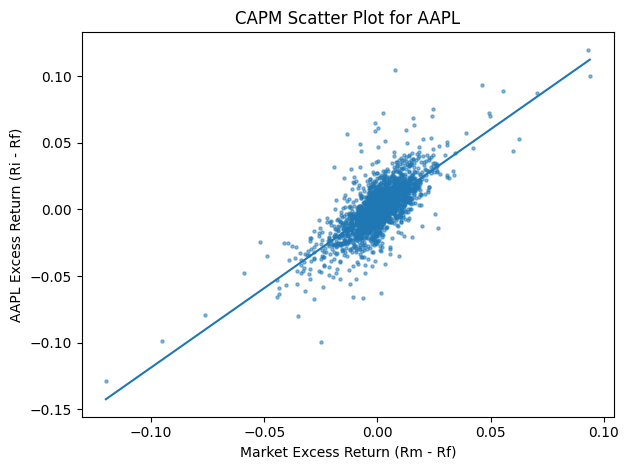

In [286]:
stock = "AAPL"
Y = ri_excess[stock]
X = rm_excess
X_with_const = sm.add_constant(X)
model = sm.OLS(Y, X_with_const).fit()

alpha = model.params["const"]
beta = model.params[0] # Corrected: Rm_excess column name in X_with_const is '0'

# 散点图
plt.scatter(X, Y, s=5, alpha=0.5)
plt.xlabel("Market Excess Return (Rm - Rf)")
plt.ylabel(f"{stock} Excess Return (Ri - Rf)")
plt.title(f"CAPM Scatter Plot for {stock}")

# 回归线：在当前 X 范围上画一条
x_line = np.linspace(X.min(), X.max(), 100)
y_line = alpha + beta * x_line
plt.plot(x_line, y_line)

plt.tight_layout()
plt.show()

We've seen how CAPM works. However, one limitation of this method is that for each stock, we use the data from 2015 to 2025 to perform the Ordinary Least Square regression and compute one single alpha, beta and R^2.

## 2. Rolling CAPM Methodology

Unlike full-sample OLS, which estimates a single set of CAPM parameters using the entire historical dataset, **rolling estimation uses only recent historical returns to update $\alpha$, $\beta$, and $R^2$ at each trading date.**

This is essential for our strategy for two reasons:

1. **Avoiding look-ahead bias:** Full-sample estimates incorporate future information unavailable at the time of trading, whereas rolling estimation uses only information available up to the signal formation date.
2. **Adapting to changing market conditions:** Stock return characteristics and market exposures may change over time. Rolling estimation allows our alpha rankings to reflect more recent information rather than relying on fixed historical estimates.

We adopt a **126-trading-day window (approximately six months)** from the original research as our baseline. This represents a trade-off between estimation stability and responsiveness, rather than a theoretically optimal choice.

At each date, the estimated rolling alpha is used to rank stocks and construct the portfolio for the following trading day.

## 3. Rolling CAPM estimation

In [287]:
window = 126 # We choose half a year as the rolling window.

In [288]:
import pandas as pd
import numpy as np

# Prepare empty dataframes, where rows are dates and columns are stocks.
alpha_rolling = pd.DataFrame(index=ri_excess.index, columns=stocks, dtype=float)
beta_rolling = pd.DataFrame(index=ri_excess.index, columns=stocks, dtype=float)
residuals_rolling = pd.DataFrame(index=ri_excess.index, columns=stocks, dtype=float)
r2_rolling = pd.DataFrame(index=ri_excess.index, columns=stocks, dtype=float)

for stock in stocks:
  # 1. We concat the excess return of this stock and the market together.
  df = pd.concat(
      [ri_excess[stock], rm_excess], axis=1, keys=["ri_excess", "rm_excess"]
  ).dropna()
  ri = df["ri_excess"]
  rm = df["rm_excess"]
  if df.empty:
    continue
    # We skip if we come to a column without data.

  # 2. Calculate mean, var, cov in the rolling window.
  mean_ri = ri.rolling(window=window).mean()
  mean_rm = rm.rolling(window=window).mean()
  var_ri = ri.rolling(window=window).var()
  var_rm = rm.rolling(window=window).var()
  cov_ri_rm = ri.rolling(window=window).cov(rm)

  # 3. Different from what we did above, in this case we can directly compute the rolling alpha, beta and epsilon(residuals) by fomulae from Ordinary Least Squares:
  beta = cov_ri_rm / var_rm
  alpha = mean_ri - beta * mean_rm
  residuals = ri - (alpha + beta * rm)

  # 4. We write this into the rolling table
  beta_rolling.loc[df.index, stock] = beta
  alpha_rolling.loc[df.index, stock] = alpha
  residuals_rolling.loc[df.index, stock] = residuals

  # 5. We get rolling R^2. For simple linear regression, by algebraicly simplification, we can get R^2 = cov(Ri,Rm)^2 / (var(Ri) * var(Rm))
  denom = var_ri * var_rm

  with np.errstate(divide='ignore', invalid='ignore'):
    r2 = (cov_ri_rm ** 2) / denom
  r2 = r2.where(denom > 0)   # return NaN except denom >0
  r2_rolling.loc[df.index, stock] = r2


## 4. Signal Output

In [289]:
alpha_rolling

,AAPL,MSFT,NVDA,GOOGL,META,TSLA,ADBE,ORCL,CRM,JPM,...,DUK,SO,AEP,T,VZ,NFLX,CMCSA,PLD,O,SPG
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,0.000894,-0.000979,-0.000656,-0.000272,0.000516,0.005567,-0.002050,0.000928,0.001997,0.001086,...,0.000838,0.000685,0.000712,0.001988,0.000079,0.001825,-0.000237,-0.000770,0.000298,0.000951
2024-12-26,0.000897,-0.001002,-0.000494,-0.000346,0.000372,0.005413,-0.002268,0.000842,0.001631,0.001053,...,0.000738,0.000670,0.000579,0.001993,0.000149,0.001689,-0.000274,-0.000662,0.000310,0.000860
2024-12-27,0.000971,-0.000978,-0.000482,-0.000253,0.000645,0.005142,-0.002395,0.000723,0.001485,0.000914,...,0.000769,0.000744,0.000665,0.001784,0.000052,0.001712,-0.000497,-0.000824,0.000180,0.000706


In [290]:
beta_rolling

,AAPL,MSFT,NVDA,GOOGL,META,TSLA,ADBE,ORCL,CRM,JPM,...,DUK,SO,AEP,T,VZ,NFLX,CMCSA,PLD,O,SPG
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,0.882554,1.067947,2.620273,1.190008,1.284879,2.902998,1.214492,1.268568,1.239090,0.953207,...,-0.021932,-0.108388,-0.144951,-0.196342,-0.056599,1.054809,0.628724,0.703740,-0.017016,0.728470
2024-12-26,0.882213,1.068095,2.620512,1.190152,1.285638,2.905663,1.213229,1.268303,1.239843,0.952809,...,-0.021148,-0.107799,-0.144571,-0.196110,-0.057012,1.055937,0.629127,0.701007,-0.016535,0.728102
2024-12-27,0.880870,1.069664,2.614046,1.185437,1.264641,2.936195,1.215571,1.276907,1.246544,0.959937,...,-0.022386,-0.113182,-0.151237,-0.178359,-0.050183,1.059861,0.642749,0.714956,-0.003583,0.739049


In [291]:
r2_rolling

,AAPL,MSFT,NVDA,GOOGL,META,TSLA,ADBE,ORCL,CRM,JPM,...,DUK,SO,AEP,T,VZ,NFLX,CMCSA,PLD,O,SPG
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,0.367823,0.534075,0.502615,0.364887,0.353384,0.333030,0.254297,0.323785,0.315612,0.241564,...,0.000344,0.008478,0.013307,0.017076,0.001380,0.293633,0.113620,0.167072,0.000207,0.222411
2024-12-26,0.367649,0.534195,0.504280,0.365483,0.354208,0.332857,0.259221,0.324666,0.324419,0.241692,...,0.000319,0.008380,0.013357,0.017041,0.001401,0.293742,0.113731,0.163777,0.000196,0.223917
2024-12-27,0.372503,0.538753,0.505863,0.367757,0.353546,0.339548,0.264438,0.331042,0.332144,0.248780,...,0.000362,0.009369,0.014815,0.014426,0.001103,0.298169,0.121650,0.171448,0.000009,0.233429


---

# IV. Strategy Construction

## 0. Overview

The rolling CAPM step gives us a time-varying estimate of each stock's abnormal performance: $\hat{α}_{i,t}$

At this stage, the model estimation is complete. We now use the rolling alpha estimates to construct and backtest the trading strategy.

The strategy follows the original research design:

1. Cross-sectional ranking: At each date $t$, rank all stocks by their estimated rolling CAPM alpha.
2. Stock selection: Select the top $\Omega%$ of stocks with the highest alpha.
Positioning: Allocate the portfolio equally across the selected stocks with valid data.
3. Time alignment: A signal computed using information available at $t$ is applied to subsequent returns, avoiding look-ahead bias.
4. Portfolio return: Calculate the portfolio return from the weighted returns of the selected stocks.
5. Rebalancing: After $p$ trading days, recompute the alpha rankings and update the portfolio.

The baseline strategy will initially use:

$$
\text{Lookback}=126\text{ trading days},
\qquad
\Omega=10\%,
\qquad
p=1\text{ day}.
$$

The purpose of this first version is to reproduce the basic alpha-ranking strategy before introducing transaction costs, robustness tests, or additional signals such as beta.

##1. Cross-sectional ranking

In [292]:
import numpy as np
import pandas as pd

omega = 0.10
n_select = max(1, int(np.ceil(len(stocks) * omega)))

ranked_alpha = alpha_rolling.rank(axis=1, ascending=False, method="first")
# method = "first": ensure the result is reproducible by ordering by the original order when alpha value is the same.

selected = (ranked_alpha <= n_select)
# selected: a bool DataFrame, showing each day if the stock is chosen.

## 2. Stock Selection

In [293]:
valid_days = alpha_rolling.notna().sum(axis = 1) >= n_select
# valid_days is a booliean time series, showing if each day is a valid trading day
# We use sum(axis = 1) function to see if the number of valid stocks of that day and then we compare it with n_select to see if there are enough stocks that we could trade.

weights_signal = selected.astype(float)
# .astype() convert the data into float numbers, make it easier for the division

'''
weights_signal = weights_signal.div(
    weights_signal.sum(axis=1).replace(0, np.nan), axis=0
).fillna(0.0)

# div means division for DataFrame
# sum(axis=1) means summation in rows, showing how many stocks we choose each day.
# div(..., axis=0) is to normalise the weight we choose, we devide the sum of weight by column
# That is, we use weights signal(1 or 0) to devide the total numbers chosen, then we get the weight for each stock.
# to avoid division of 0, we replace 0 with NaN, while after the divion we convert NaN back to 0
# it makes sense that we set the days with weights_signal 0 with 0 weight
# further speaking, that shows the strategy is to select top Ω of the stocks and chose the ones with valid features to trade
'''
# Actually since we would enforce the invalid days with 0 position, we can just use a much simpler way for position attribution:
weights_signal = selected.astype(float) / n_select

weights_signal.loc[~valid_days] = 0.0
# ~means "inverse" in boolean calculations. This line search all the invalid days and set the positioning to be 0

In this way, we construct a portfolio weighting, assigning even weight to each of the stocks chosen.

## 3. Time-alignment

Signals are lagged by one trading day before being applied to subsequent close-to-close returns. This represents a simplified execution convention with the spirit to reduce look-ahead bias; actual execution timing and next-day price movements are not fully modelled.

In [294]:
weights_held = weights_signal.shift(1).fillna(0.0)

## 4. Calculate Portfolio Return

The daily portfolio return is calculated as the weighted sum
of individual stock returns:

$$
R_{p,t} = \sum_{i=1}^{N} w_{i,t}^{\mathrm{held}} R_{i,t}
$$

where:
- $R_{p,t}$ is the portfolio return on day $t$.
- $w_{i,t}^{\mathrm{held}}$ is the portfolio weight of stock $i$ applied to day $t$.
- $R_{i,t}$ is the daily return of stock $i$ on day $t$.

In [295]:
stock_returns = returns[stocks].reindex(
    index=weights_held.index,
    columns=weights_held.columns
) # realign the columns and rows of stock_returns by weights_held (unify the order; handle NaN)
portfolio_return = (
    weights_held * stock_returns # element-wise multiplication
).sum(axis=1, min_count=1) # We add up the return of all stocks we deal with in one day. This is our Portfolio Return time series
# min_count ensures the portfolio_return comes from at least 1 non NaN value

The part below is just a further check on NaN values.

In [296]:
missing_held_returns = (
    (weights_held > 0) &
    stock_returns.isna()
)

In [297]:
missing_count = missing_held_returns.sum().sum()

print("Missing held returns:", missing_count)

Missing held returns: 0


In [298]:
print(stock_returns.isna().sum().sum())
print(weights_held.isna().sum().sum())

0
0


Now we do a check on the portfolio we've constructed to see how the return value is like, at which day we start to hold, if the weight sum is right and more detailes about the day with extreme returns.

In [299]:
print(portfolio_return.describe())
print(portfolio_return.head())

count    2515.000000
mean        0.001102
std         0.015174
min        -0.158198
25%        -0.005373
50%         0.001137
75%         0.008681
max         0.087717
dtype: float64
Date
2015-01-05    0.0
2015-01-06    0.0
2015-01-07    0.0
2015-01-08    0.0
2015-01-09    0.0
dtype: float64


In [300]:
active_days = weights_held.sum(axis=1) > 0

print("First trading date:", active_days[active_days].index[0])
print("Number of active days:", active_days.sum())

First trading date: 2015-07-07 00:00:00
Number of active days: 2389


In [301]:
weight_sums = weights_held.sum(axis=1)

print(weight_sums[active_days].describe())

count    2.389000e+03
mean     1.000000e+00
std      4.738465e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64


In [302]:
worst_date = portfolio_return.idxmin()

print("Worst date:", worst_date)
print("Portfolio return:", portfolio_return.loc[worst_date])

print(weights_held.loc[worst_date])
print(stock_returns.loc[worst_date])

Worst date: 2020-03-16 00:00:00
Portfolio return: -0.15819807173360995
AAPL     0.166667
MSFT     0.000000
NVDA     0.166667
GOOGL    0.000000
META     0.000000
TSLA     0.166667
ADBE     0.166667
ORCL     0.000000
CRM      0.000000
JPM      0.000000
BAC      0.000000
GS       0.000000
MS       0.000000
C        0.000000
WFC      0.000000
AXP      0.000000
XOM      0.000000
CVX      0.000000
COP      0.000000
SLB      0.000000
PSX      0.000000
OXY      0.000000
AMZN     0.000000
HD       0.000000
MCD      0.000000
NKE      0.000000
COST     0.000000
SBUX     0.000000
DIS      0.000000
JNJ      0.000000
UNH      0.166667
PFE      0.000000
MRK      0.000000
ABBV     0.166667
TMO      0.000000
BA       0.000000
CAT      0.000000
HON      0.000000
MMM      0.000000
GE       0.000000
LMT      0.000000
LIN      0.000000
SHW      0.000000
APD      0.000000
ECL      0.000000
NEE      0.000000
DUK      0.000000
SO       0.000000
AEP      0.000000
T        0.000000
VZ       0.000000
NFLX     0.

## 5. Cumulative Performance


### 5.1. Data Cleaning

Since the rolling CAPM requires 126 trading days of historical observations, the strategy cannot generate valid trading signals during the initial estimation period. We therefore exclude the days before the portfolio first becomes active when evaluating strategy performance.




In [303]:
active_days = weights_held.sum(axis=1) > 0
strategy_returns = portfolio_return.loc[active_days]

### 5.2. Calculating Cumulative Wealth

Assuming an initial portfolio value of 1, we calculate cumulative wealth by compounding daily portfolio returns:

$$
W_t = \prod_{s=1}^{t}(1+R_{p,s})
$$

where $R_{p,s}$ represents the portfolio return on trading day $s$.


In [304]:
wealth = (1 + strategy_returns).cumprod()

### 5.3. Calculating Cumulative Return

The cumulative return is obtained by subtracting the initial portfolio value from cumulative wealth:

$$
C_t = W_t - 1
$$

For example, a cumulative return of 2.0 represents a total return of 200%, meaning the portfolio value has increased from 1 to 3.

This produces a cumulative return series that allows us to visualize the strategy's historical performance over the backtesting period.

Note: The initial backtest excludes transaction costs and assumes daily portfolio rebalancing under a simplified execution model. The resulting performance should therefore be interpreted as a preliminary gross-return estimate rather than a fully implementable trading result.

In [305]:
cumulative_return = wealth - 1

### 5.4. Plotting

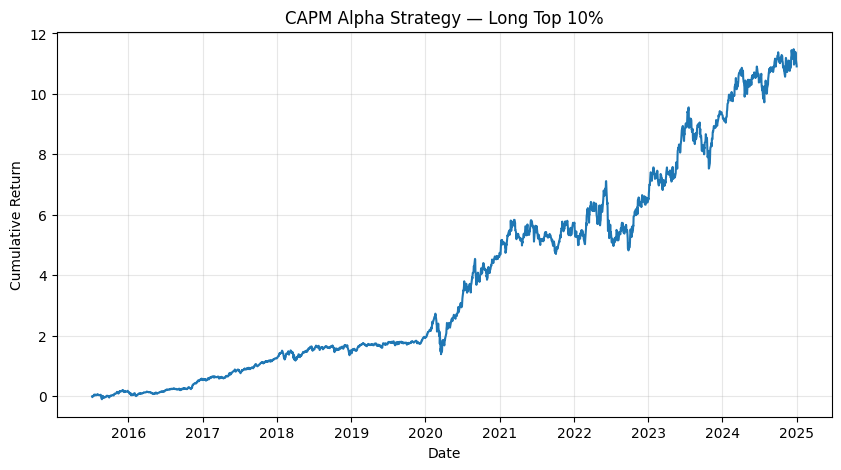

In [306]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(cumulative_return.index, cumulative_return)

plt.title("CAPM Alpha Strategy — Long Top 10%")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")
plt.grid(alpha=0.3)

plt.show()

This graph is not really alike the one we did in the project. The reason why this happens is probably that in our original version, we just cumulated all the sum of return together. However, this time I modified by taking compound interest into consideration, giving out a result closer to the reality while showing a better return.

In [307]:
import yfinance as yf
import inspect

print("yfinance version:", yf.__version__)
print(inspect.signature(yf.download))

yfinance version: 0.2.66
(tickers, start=None, end=None, actions=False, threads=True, ignore_tz=None, group_by='column', auto_adjust=None, back_adjust=False, repair=False, keepna=False, progress=True, period=None, interval='1d', prepost=False, proxy=<object object at 0x7ab61e9f62a0>, rounding=False, timeout=10, session=None, multi_level_index=True) -> Optional[pandas.core.frame.DataFrame]


In [308]:
print(prices["^IRX"].head(10))
print(prices["^IRX"].describe())

Date
2015-01-02    0.015
2015-01-05    0.003
2015-01-06    0.020
2015-01-07    0.020
2015-01-08    0.018
2015-01-09    0.015
2015-01-12    0.013
2015-01-13    0.023
2015-01-14    0.025
2015-01-15    0.023
Name: ^IRX, dtype: float64
count    2515.000000
mean        1.756887
std         1.866024
min        -0.105000
25%         0.110000
50%         1.055000
75%         2.389000
max         5.348000
Name: ^IRX, dtype: float64


### 5.5. Sanity Audit

Used the mean risk-free rate across all the days and the stock universe is actually based on the stocks in S&P 500 pool at December 2025. Both acts leads to a look-ahead bias, which would be further illustrated in the Limitations and Improvements part.

---

# V. Performance Evaluation

## 0. Overview

Having constructed the portfolio return series and verified the basic portfolio accounting, we now evaluate the historical performance of the CAPM alpha strategy.

The evaluation focuses on both absolute and risk-adjusted returns, using the following metrics:

**Compound Annual Growth Rate (CAGR)**: Measures the annualized compounded growth of the portfolio.

**Annualized Volatility**: Measures the variability of daily portfolio returns.

**Sharpe Ratio**: Evaluates excess returns relative to total portfolio risk.

**Maximum Drawdown**: Measures the largest peak-to-trough decline in portfolio wealth.

**Portfolio Turnover**: Measures the frequency and magnitude of portfolio rebalancing.

**Benchmark Comparison**: Compares the strategy against a passive S&P 500 investment over the same period.

The current results are preliminary and exclude transaction costs. The initial implementation also uses a full-sample average risk-free rate and a retrospectively selected stock universe, which may introduce look-ahead and selection biases. These limitations will be addressed in subsequent robustness and methodology improvements.

## 1. CAGR

From definition of CAGR aka the compound growth formula:

$$
(1+\mathrm{CAGR})^Y=\frac{W_T}{W_0}
$$


Therefore we could derive CAGR by:

$$
\boxed{\mathrm{CAGR}=\left(\frac{W_T}{W_0}\right)^{1/Y}-1}
$$

Assuming $W_0=1$ and $Y=T/252$, where $T$ is the number of trading days, we would have:

$$
\boxed{\mathrm{CAGR}=W_T^{252/T}-1}
$$

In [309]:
def CAGR(T, W_t, W_0):
  return (W_t / W_0) ** (252 / T) - 1

In [310]:
cagr = CAGR(T=len(cumulative_return), W_t=wealth.iloc[-1], W_0=1)
print(f"CAGR: {cagr:.2%}")

CAGR: 29.86%


## 2. Annualised standard deviation:
According to the linearity of variance (provided covariance is 0), we obtain:

$$
\boxed{\sigma_{\text{annual}}=\sqrt{252}\,\sigma_{\text{daily}}}
$$

In [311]:
annual_vol = strategy_returns.std() * np.sqrt(252)
print(f"Annualized Volatility: {annual_vol:.2%}")

Annualized Volatility: 24.71%


In [312]:
returns

Ticker,AAPL,MSFT,NVDA,GOOGL,META,TSLA,ADBE,ORCL,CRM,JPM,...,SO,AEP,T,VZ,NFLX,CMCSA,PLD,O,SPG,^GSPC
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-05,-0.028172,-0.009196,-0.016890,-0.019054,-0.016061,-0.042041,-0.004976,-0.014024,-0.018062,-0.031045,...,-0.004253,-0.014718,-0.009448,-0.008305,-0.050897,-0.020394,-0.000691,0.020568,0.004101,-0.018278
2015-01-06,0.000094,-0.014677,-0.030318,-0.024679,-0.013473,0.005664,-0.020145,-0.010324,-0.016675,-0.025929,...,0.012001,0.005477,0.001490,0.010092,-0.017121,-0.013045,0.003457,0.013100,0.027834,-0.008893
2015-01-07,0.014022,0.012705,-0.002606,-0.002941,0.000000,-0.001562,0.008223,0.000232,-0.004720,0.001526,...,0.011055,0.014196,0.005831,-0.006453,0.005192,-0.000905,0.015155,0.016312,0.018402,0.011630
2015-01-08,0.038423,0.029418,0.037618,0.003484,0.026658,-0.001564,0.025453,0.006026,0.029158,0.022346,...,0.000795,0.008626,0.009949,0.021433,0.022188,0.021747,0.000226,-0.026424,-0.001437,0.017888
2015-01-09,0.001072,-0.008405,0.004028,-0.012211,-0.005628,-0.018802,-0.014811,-0.000461,-0.007339,-0.017387,...,-0.012714,-0.005325,-0.002985,-0.008902,-0.015458,-0.001596,-0.001583,0.011861,0.010539,-0.008404
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-24,0.011478,0.009374,0.003938,0.007604,0.013170,0.073572,0.002686,0.013421,0.004462,0.016444,...,0.001445,-0.005277,0.004816,-0.003505,0.022678,0.011058,0.005377,0.004528,0.011495,0.011043
2024-12-26,0.003176,-0.002777,-0.002068,-0.002601,-0.007240,-0.017630,0.004956,0.001575,-0.007868,0.003425,...,-0.003848,-0.003356,0.000436,0.004020,-0.008561,-0.003906,0.020917,-0.003193,0.002596,-0.000406
2024-12-27,-0.013242,-0.017302,-0.020868,-0.014520,-0.005867,-0.049479,-0.008175,-0.015843,-0.009569,-0.008102,...,0.003621,0.004888,-0.004355,-0.001001,-0.017952,-0.008366,-0.015436,-0.007726,-0.010299,-0.011056


## 3. Sharpe Ratio

We use all $T=2389$ daily portfolio returns from the backtesting period to calculate the following statistics.

### 3.1. Mean Daily Excess Return

$$
\bar{R}_e = \frac{1}{T}\sum_{t=1}^{T}(R_{p,t}-R_{f,t})
$$

### 3.2. Standard Deviation of Daily Excess Returns

$$
s_e = \sqrt{\frac{1}{T-1}\sum_{t=1}^{T}(R_{e,t}-\bar{R}_e)^2}
$$

### 3.3. Daily Sharpe Ratio

$$
Sharpe Ratio_{\text{daily}} = \frac{\bar{R}_e}{s_e}
$$

### 3.4. Annualized Sharpe Ratio

Multiplying the daily Sharpe Ratio by $\sqrt{252}$, we obtain:

$$
\boxed{Sharpe Ratio_{\text{annualized}} = \sqrt{252}\frac{\bar{R}_e}{s_e}}
$$

In [313]:
def Sharpe(T, R_i, R_f):
  R_e = R_i - R_f
  return R_e.mean() / R_e.std(ddof=1) * np.sqrt(252)
# Here we use ddof = 1 to get the unbiased standard deviation(i.e., the one deviding T-1).
# We do so with the spirit that we assume ourselves doing a statistical inference, rather than just giving a descriptive statistics.
# Furthermore, we do this statistlical inference under the assumption that the excess return each day has an independent identical distribution, which is unrealistic.
# In this project we have a provisional purpose of estimate the fluctuation of the returns and use it to assess the characteristics of potential returns. Hence we use 1/N-1.

In [314]:
rf_aligned = rf_daily.reindex(strategy_returns.index)
# reindex rf to avoid NaN which may be outside of the active period of this strategy.
sharpe = Sharpe(T=len(strategy_returns), R_i = strategy_returns, R_f = rf_aligned)
print(f"Sharpe Ratio: {sharpe:.2f}")

Sharpe Ratio: 1.11


## 4. Maximum Drawdown


Drawdown measures the percentage decline in portfolio wealth relative to its historical running peak:

$$
\boxed{
DD_t = \frac{W_t}{\max_{0 \leq s \leq t} W_s} - 1
}
$$

The Maximum Drawdown is the minimum value of the drawdown time series:

$$
\boxed{
MDD = \min_{0 \leq t \leq T} DD_t
}
$$
( We use minimum here as Drawdown is supposed to be a time series of non-positive numbers)

In [315]:
def MaxDrawdown(R):
  def Drawdown(R):
    peak = []
    peak.append(1.0) # The amount of portfolio on Day 0
    drawdowns = []

    for t in range(len(R)):
      peak.append(max(peak[t], R.iloc[t]))
      drawdown = (R.iloc[t] - peak[t + 1]) / peak[t + 1]
      drawdowns.append(drawdown)
    return pd.Series(drawdowns, index=R.index)

  return Drawdown(R).min()

  # Note in this part the drawdown has the same length with the return.
  # As we the return starts at day 1(i.e., return[0] is the return of the 1st day) and ends at day N, while the drawdown is calculated from 0→1 to 0→n

In [316]:
maxdrawdown = MaxDrawdown(wealth)
print(f"Maximum Drawdown: {maxdrawdown:.2%}")


Maximum Drawdown: -35.96%


## 5. Turnover

### 5.1. Turnover Calculations

Portfolio turnover measures the extent to which portfolio holdings change between consecutive rebalancing dates. For our long-only, fully invested strategy, we use the **one-sided turnover convention**:

$$
\boxed{\mathrm{Turnover}_t = \frac{1}{2}\sum_{i=1}^{N}\left|w_{i,t}-w_{i,t-1}\right|}
$$

where $w_{i,t}$ is the target portfolio weight of stock $i$ at time $t$.


We are using 50% turnover as we assume in such a fully invested long-only portfolio with **no external cash flows**, rebalancing generally involves selling some holdings to finance purchases of others. When total portfolio weights remain at 100%, the sum of positive weight changes equals the absolute sum of negative weight changes. Therefore, summing all absolute weight changes counts both the buying and selling sides. Multiplying by $1/2$ measures the one-sided turnover, approximately representing the proportion of the portfolio being replaced.


**Limitation:** This is a target-weight-change approximation. Actual turnover should account for changes in portfolio weights caused by asset returns before rebalancing. Initial portfolio establishment also requires separate treatment.

In [317]:
def Turnover(w):
  previous_weight = w.shift(1).fillna(0.0)
  # We need a previous weight as if we shift w[0] by 1 it would be NaN
  daily_turnover = w - previous_weight
  sum_turnover = daily_turnover.abs().sum(axis=1)
  return 1/2 * sum_turnover


We calculate daily turnover.

In [318]:
turnover = Turnover(weights_held)

print(turnover.describe())


count    2515.000000
mean        0.086879
std         0.101348
min         0.000000
25%         0.000000
50%         0.000000
75%         0.166667
max         0.500000
dtype: float64


We then calculate annual turnover based on the daily data.

In [319]:
# Now we want to analyse the daily turnover. During the first day we bought 100% of the stocks, while it is an outlier and we do not wish to conclude it at the performance analyse part(but we will consider it for the transaction cost part)

# Below we exclude the first index of turnover to get a more fair evaluation of the turnover rate and wrap it up in a single function.

def Averagedailyturnonver(weights_held):
  turnover = Turnover(weights_held)

  # Find the first date with an active portfolio
  first_trade_date = weights_held.index[(weights_held.sum(axis=1) > 0)][0]

  # Exclude the initial portfolio construction and warm-up period
  rebalance_turnover = turnover.loc[turnover.index > first_trade_date]
  # Calculate average daily turnover
  average_daily_turnover = rebalance_turnover.mean()
  return average_daily_turnover


In [320]:
average_daily_turnover = Averagedailyturnonver(weights_held)
print(f"Average Daily Turnover: {average_daily_turnover:.2%}")

Average Daily Turnover: 9.13%


### 5.2. Transaction Cost Implications

Given an average daily one-sided turnover of $9.13\%$, we assume a transaction cost of 10 basis points (bps) per unit of traded notional:

$$
c = 0.001
$$

Since we use the one-sided turnover convention, the estimated daily transaction cost is:

$$
TC_{\text{daily}} \approx 2c \times \overline{\text{Turnover}}
= 2 \times 0.001 \times 0.0913
= 0.0001826
$$

This corresponds to approximately **1.826 bps per day**.

The approximate annualized transaction cost drag is:

$$
TC_{\text{annual}} \approx 252 \times 0.0001826
= 4.60\%
$$

This suggests that transaction costs could materially reduce strategy profitability. However, this is a simplified estimate based on target-weight changes, excluding weight drift, market impact, and other trading frictions.

## 6. Benchmark Comparison

To evaluate whether our CAPM alpha strategy provides additional value beyond passive market exposure, we compare its historical performance against the **S&P 500 Index**, using `^GSPC` as the market benchmark.

### 6.1. Data Alignment

Since our strategy begins trading only after the 126-day rolling estimation window, the benchmark returns must be aligned with the strategy's active trading period.

Both return series are therefore evaluated over the same dates to ensure a consistent comparison.

### 6.2. Cumulative Performance

The benchmark's cumulative wealth is calculated by compounding its daily returns:

$$
W_t^{benchmark}=\prod_{s=1}^{t}(1+R_{m,s})
$$

The cumulative return is then:

$$
C_t^{benchmark}=W_t^{benchmark}-1
$$

where $R_{m,s}$ represents the S&P 500 daily return on day $s$.

### 6.3. Performance Metrics

We compare the strategy and benchmark using the same performance measures:

- **CAGR:** Long-term compounded growth.
- **Annualized Volatility:** Total return variability.
- **Annualized Sharpe Ratio:** Risk-adjusted excess return.
- **Maximum Drawdown:** Largest historical peak-to-trough decline.

### 6.4. Interpretation and Limitations

The comparison helps assess whether the CAPM alpha-ranking strategy outperformed a passive market investment during the backtesting period.

However, outperformance alone does not establish genuine alpha, as differences may arise from market beta, sector concentration, portfolio construction, and other risk exposures.

Furthermore, `^GSPC` is a price index that excludes reinvested dividends, while our stock returns may be dividend-adjusted. This difference in return conventions should be considered when interpreting the results. A total-return benchmark would provide a more consistent comparison.

The current strategy performance is also reported before transaction costs and remains subject to the methodological limitations identified in the preliminary backtest.

In [321]:
# We realign the benchmark returns' index with the trading period.
benchmark_returns = returns[market_index].reindex(
    strategy_returns.index
)

In [322]:
# We calculate the benchmark's cumulative wealth
benchmark_wealth = (1 + benchmark_returns).cumprod()
benchmark_cumulative_return = benchmark_wealth - 1

We compare the strategy and benchmark using the same performance measures:

- **CAGR:** Long-term compounded growth.
- **Annualized Volatility:** Total return variability.
- **Annualized Sharpe Ratio:** Risk-adjusted excess return.
- **Maximum Drawdown:** Largest historical peak-to-trough decline.

In [323]:
benchmark_cagr = CAGR(len(benchmark_wealth), benchmark_wealth.iloc[-1], 1)
print(f"Benchmark CAGR: {benchmark_cagr:.2%}")

Benchmark CAGR: 11.65%


In [324]:
benchmark_annual_vol = benchmark_returns.std() * np.sqrt(252)
print(f"Benchmark Annualized Volatility: {benchmark_annual_vol:.2%}")

Benchmark Annualized Volatility: 18.08%


In [325]:
benchmark_rf_aligned = rf_daily.reindex(benchmark_returns.index)
# reindex rf to avoid NaN which may be outside of the active period of this strategy.
benchmark_sharpe = Sharpe(T=len(benchmark_rf_aligned), R_i=benchmark_returns, R_f=benchmark_rf_aligned)
print(f"Benchmark Sharpe Ratio: {benchmark_sharpe:.2f}")

Benchmark Sharpe Ratio: 0.60


In [326]:
benchmark_maxdrawdown = MaxDrawdown(benchmark_wealth)
print(f"Maximum Drawdown: {benchmark_maxdrawdown:.2%}")

Maximum Drawdown: -33.92%


## 7.Preliminary Research Findings

The CAPM alpha-ranking strategy outperformed the S&P 500 benchmark over the backtesting period, achieving a CAGR of **29.86%** compared with **11.65%** for the benchmark.

Although the strategy exhibited higher annualized volatility (24.71% versus 18.08%), it also achieved a higher Sharpe Ratio (1.11 versus 0.60), suggesting stronger risk-adjusted performance under the current backtesting assumptions.

Interestingly, the strategy's Maximum Drawdown (-35.96%) was only slightly more severe than that of the benchmark (-33.92%), despite its higher overall volatility.

However, the strategy exhibited an average daily one-sided turnover of 9.13%, indicating that transaction costs could materially reduce its net profitability.

These findings are preliminary. The backtest excludes transaction costs and remains subject to methodological limitations, including retrospective stock selection, risk-free-rate look-ahead bias, and differences in dividend treatment between the strategy and benchmark.

Further research is required to determine whether the observed outperformance persists after controlling for these limitations and broader market risk exposures.

In [327]:
performance_table = pd.DataFrame({
    "Metric": [
        "CAGR",
        "Annualized Volatility",
        "Annualized Sharpe",
        "Maximum Drawdown",
        "Average Daily Turnover"
    ],
    "CAPM Alpha Strategy": [
        cagr,
        annual_vol,
        sharpe,
        maxdrawdown,
        average_daily_turnover
    ],
    "S&P 500": [
        benchmark_cagr,
        benchmark_annual_vol,
        benchmark_sharpe,
        benchmark_maxdrawdown,
        np.nan
    ]
})

performance_table = performance_table.set_index("Metric")

In [328]:
display(
    performance_table.style
    .format(
        "{:.2%}",
        subset=pd.IndexSlice[
            [
                "CAGR",
                "Annualized Volatility",
                "Maximum Drawdown",
                "Average Daily Turnover"
            ],
            :
        ]
    )
    .format(
        "{:.2f}",
        subset=pd.IndexSlice[
            ["Annualized Sharpe"],
            :
        ]
    )
)

,CAPM Alpha Strategy,S&P 500
Metric,,
CAGR,29.86%,11.65%
Annualized Volatility,24.71%,18.08%
Annualized Sharpe,1.11,0.60
Maximum Drawdown,-35.96%,-33.92%
Average Daily Turnover,9.13%,nan%


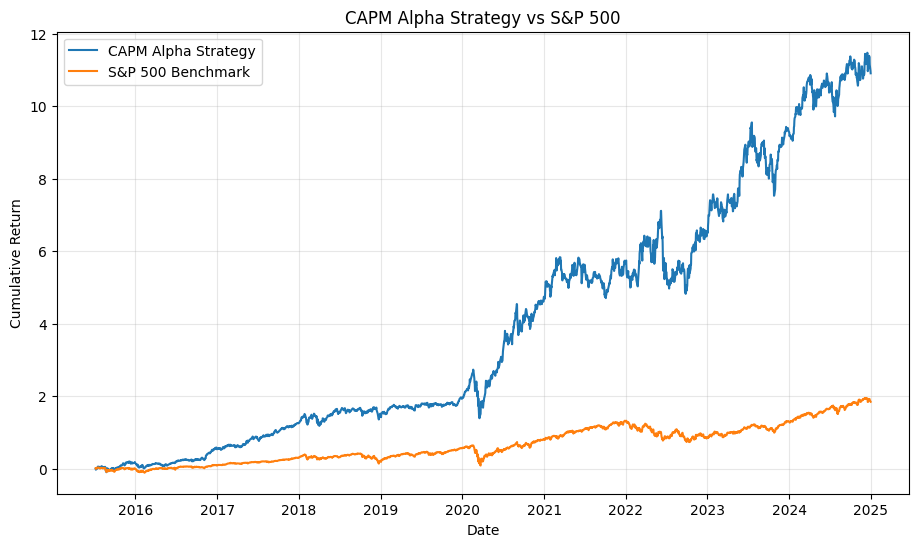

In [329]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.plot(
    cumulative_return.index,
    cumulative_return,
    label="CAPM Alpha Strategy"
)

plt.plot(
    benchmark_cumulative_return.index,
    benchmark_cumulative_return,
    label="S&P 500 Benchmark"
)

plt.title("CAPM Alpha Strategy vs S&P 500")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

---

##8. Performance Summary and Visualization

The performance comparison summarizes the historical returns and risk characteristics of the CAPM alpha-ranking strategy relative to the S&P 500 benchmark.

We report CAGR, annualized volatility, annualized Sharpe Ratio, and maximum drawdown for both portfolios. Average daily turnover is additionally reported for the active strategy to assess the potential impact of trading activity.

To visualize cumulative performance, we plot the compounded returns of the strategy and benchmark over the same investment period:

$$
C_t=\prod_{s=1}^{t}(1+R_s)-1
$$

Both series are normalized to an initial portfolio wealth of 1, allowing their cumulative growth to be compared directly.

The results represent preliminary gross performance. Transaction costs, differences in dividend treatment, and previously identified methodological biases remain important limitations.

# VI. Research Findings, Limitations and Future Research

## 1. Research Findings

This study investigates a quantitative equity strategy based on cross-sectional rankings of rolling Capital Asset Pricing Model (CAPM) alpha estimates. The strategy selects the top 10% of stocks by estimated alpha, constructs an equally weighted long-only portfolio, and rebalances daily.

The preliminary backtest covers approximately July 2015 to December 2024 and evaluates the strategy against the S&P 500 Index.

### 1.1 Historical Outperformance

The CAPM alpha-ranking strategy demonstrated strong historical performance relative to the S&P 500 benchmark.

| Performance Metric | CAPM Alpha Strategy | S&P 500 |
|---|---:|---:|
| CAGR | 29.86% | 11.65% |
| Annualized Volatility | 24.71% | 18.08% |
| Annualized Sharpe Ratio | 1.11 | 0.60 |
| Maximum Drawdown | −35.96% | −33.92% |
| Average Daily One-sided Turnover | 9.13% | — |

The strategy achieved a CAGR approximately 18.21 percentage points higher than the benchmark. Its annualized Sharpe Ratio of 1.11 also exceeded the benchmark's 0.60, indicating stronger historical risk-adjusted performance under the current backtesting assumptions.

However, this outperformance should not be interpreted as conclusive evidence of persistent stock-selection alpha, as the results remain subject to methodological biases and systematic risk exposures.

### 1.2 Risk and Drawdown Characteristics

The strategy exhibited higher annualized volatility than the benchmark (24.71% versus 18.08%), indicating greater variability in daily portfolio returns.

Interestingly, its maximum drawdown of −35.96% was only slightly more severe than the benchmark's −33.92%, despite the higher overall volatility.

This suggests that the strategy's historical peak-to-trough loss was not proportionally larger than its increase in volatility. Nevertheless, maximum drawdown reflects only the most severe historical decline and does not establish consistent downside protection across different market regimes.

Overall, the strategy can be characterized as a higher-risk, higher-return portfolio with stronger preliminary risk-adjusted performance than the selected benchmark.

### 1.3 Portfolio Turnover and Trading Frictions

The strategy exhibited an average daily one-sided turnover of 9.13%, corresponding to an approximate annualized turnover of:

$$
252\times9.13\%\approx2300.76\%
$$

This suggests that frequent portfolio rebalancing may generate substantial trading costs.

Assuming a constant transaction cost of 10 basis points per unit of traded notional, the estimated average daily transaction cost is:

$$
TC_{\mathrm{daily}}
\approx2c\times\overline{\mathrm{Turnover}}
$$

$$
=2\times0.001\times0.0913
=0.0001826
$$

The approximate annualized arithmetic cost drag is therefore:

$$
TC_{\mathrm{annual}}
\approx252\times0.0001826
\approx4.60\%
$$

This estimate represents transaction costs relative to portfolio net asset value (NAV), rather than a directly calculated reduction in compounded CAGR.

The result highlights the importance of evaluating net performance rather than relying exclusively on gross backtesting returns.

### 1.4 Interpretation of the Alpha Signal

The strategy's historical results suggest that rolling CAPM alpha rankings may contain useful information for cross-sectional stock selection within the selected investment universe.

However, the strategy is long-only and does not explicitly neutralize market beta or industry exposures. Consequently, some of its outperformance may reflect systematic risk exposures, sector concentration or the historical characteristics of the selected stocks.

The current evidence therefore supports further investigation of the signal rather than a definitive conclusion that CAPM alpha estimates possess persistent predictive power.



## 2. Research Limitations

### 2.1 Transaction Costs and Execution Assumptions

The current backtest reports gross returns and excludes explicit transaction costs, bid-ask spreads, slippage, financing costs and market impact.

Portfolio turnover is approximated using changes in target weights:

$$
\mathrm{Turnover}_t
=
\frac12\sum_{i=1}^{N}
|w_{i,t}-w_{i,t-1}|
$$

However, actual trading volume depends on the difference between target weights and pre-trade portfolio weights after market movements.

Furthermore, the backtest uses a simplified daily execution convention. Although positions are shifted forward to reduce look-ahead bias, realistic execution prices, order timing and market liquidity constraints are not fully modelled.

These assumptions may overstate practically achievable performance.

### 2.2 Look-ahead Bias in Risk-free Rate Estimation

The current CAPM implementation uses a constant risk-free rate estimated from the full historical sample.

As a result, rolling alpha estimates at earlier dates indirectly incorporate information from future interest-rate observations.

This introduces look-ahead bias and weakens the point-in-time validity of the signal.

A more rigorous implementation should use historical risk-free rates that were observable at each signal formation date.

### 2.3 Survivorship and Selection Bias

The investment universe consists of a retrospectively selected group of prominent US equities across multiple industries.

This approach may exclude companies that were delisted, acquired or otherwise absent from the selected universe, introducing survivorship and selection biases.

Consequently, the observed historical performance may not be representative of a portfolio constructed using only information available at the beginning of the backtesting period.

A point-in-time investment universe would provide a more reliable basis for evaluating historical stock-selection performance.

### 2.4 Benchmark Consistency

The strategy uses dividend-adjusted stock prices, whereas the S&P 500 benchmark represented by `^GSPC` is a price index that excludes reinvested dividends.

This difference creates an inconsistency in the return measurement conventions and may overstate the strategy's relative performance.

A more appropriate comparison would use an S&P 500 Total Return Index or a suitably adjusted index-tracking ETF.

Both the strategy and benchmark should also be evaluated over identical dates and under clearly defined investment assumptions.

### 2.5 Market and Industry Exposure

Although the strategy uses CAPM alpha estimates to rank stocks, its long-only portfolio construction does not guarantee market or industry neutrality.

Stocks with high estimated alpha may also exhibit elevated market beta or belong disproportionately to sectors that performed strongly during the evaluation period.

Consequently, the strategy's outperformance may partly reflect market exposure, sector allocation or other systematic risk factors rather than purely stock-specific alpha.

Further performance attribution is required to distinguish these effects.

### 2.6 Single-Factor CAPM Specification and Signal Stability

The current methodology relies on a single-factor CAPM regression, which may not fully capture the systematic drivers of individual stock returns.

Additional factors, such as company size, value, momentum and industry effects, may influence the interpretation of estimated alpha.

Furthermore, financial returns may exhibit time-varying volatility and residual heteroskedasticity. Changes in market regimes may affect the statistical precision and stability of rolling alpha estimates.

These issues have not yet been formally tested and should be treated as potential model limitations rather than established empirical findings.

### 2.7 Parameter Sensitivity and Out-of-Sample Validation

The current strategy uses a 126-day rolling estimation window, a 10% selection threshold, equal portfolio weights and daily rebalancing.

Its performance may be sensitive to these methodological choices.

Moreover, the strategy has not yet been evaluated using a genuinely untouched out-of-sample period with specifications fixed in advance.

Consequently, the historical results may be affected by parameter selection, data mining or overfitting.



## 3. Future Research

Future research should prioritize methodological credibility, economic interpretability and practical implementability rather than simply maximizing historical returns.

### 3.1 Improved Data and Backtesting Methodology

The first priority is to address the identified methodological limitations.

Potential improvements include:

- Replacing the full-sample average risk-free rate with point-in-time Treasury yield observations.
- Constructing a historical investment universe that reduces survivorship and selection biases.
- Using a consistent total-return benchmark.
- Improving data quality checks, return alignment and execution assumptions.

These modifications would establish a more reliable baseline before introducing additional strategy complexity.

### 3.2 Transaction Cost Sensitivity and Rebalancing Frequency

Given the observed average daily turnover of 9.13%, transaction costs represent an important area for further investigation.

Future research could incorporate explicit transaction cost assumptions and compare gross and net strategy performance.

Additionally, alternative rebalancing frequencies could be examined to determine whether less frequent trading reduces costs without materially weakening the alpha signal.

For example, daily, weekly and biweekly rebalancing schedules could be compared using CAGR, Sharpe Ratio, Maximum Drawdown and Turnover.

### 3.3 Time-decayed Alpha Signals

The current strategy ranks stocks using their most recent rolling CAPM alpha estimates.

However, short-term fluctuations in estimated alpha may cause unnecessary changes in portfolio composition.

One potential improvement is to construct a smoothed alpha signal incorporating historical observations:

$$
\widetilde{\alpha}_{i,t}
=
\frac{
\sum_{k=0}^{L-1}\lambda_k\alpha_{i,t-k}
}{
\sum_{k=0}^{L-1}\lambda_k
}
$$

where $L$ represents the smoothing window and $\lambda_k$ determines the importance of historical alpha estimates.

Both linear and exponential decay schemes could be investigated.

The central research hypothesis is that signal smoothing may reduce ranking instability and portfolio turnover while preserving useful predictive information.

However, excessive smoothing could delay the strategy's response to new information.

### 3.4 Selection Threshold and Portfolio Diversification

The current strategy selects the top 10% of stocks according to rolling CAPM alpha.

Future research could investigate alternative selection thresholds:

$$
\Omega\in\{10\%,20\%,30\%\}
$$

Increasing the number of selected stocks may reduce portfolio concentration and individual position sizes, potentially improving diversification and reducing market impact.

However, a broader selection threshold may dilute the alpha signal or alter turnover.

These competing effects should be evaluated empirically rather than assuming that greater diversification necessarily improves performance.

### 3.5 Liquidity Filtering

A further extension is to introduce a minimum liquidity requirement before constructing the portfolio.

One possible measure is Average Daily Dollar Volume (ADV):

$$
ADV_{i,t}^{(20)}
=
\frac1{20}
\sum_{k=0}^{19}
P_{i,t-k}V_{i,t-k}
$$

where $P_{i,t}$ represents the stock price and $V_{i,t}$ represents trading volume.

Liquidity filtering may help exclude stocks with higher potential execution costs, wider bid-ask spreads or greater market impact.

Future experiments should assess whether this improves net performance and implementability without excessively restricting the investment universe.

### 3.6 Alternative Portfolio Weighting

The current strategy allocates equal weights to all selected stocks, regardless of differences in estimated alpha or individual stock risk.

Future research could compare alternative weighting schemes, including:

- Alpha-proportional weighting.
- Rank-based weighting.
- Inverse-volatility weighting.
- Risk-constrained portfolio allocation.

These methods may allow the portfolio to incorporate additional information about signal strength and risk.

However, estimated CAPM alpha may be noisy, and more aggressive weighting could increase concentration and estimation risk.

Position limits and signal normalization may therefore be necessary.

### 3.7 Industry-level Signal Neutralization

A potential extension is to neutralize rolling CAPM alpha estimates within each industry group.

Instead of ranking stocks exclusively by raw estimated alpha, we can subtract the corresponding industry mean:

$$
\alpha_{i,t}^{neutral}
=
\alpha_{i,t}
-
\frac{1}{N_{g(i),t}}
\sum_{j\in g(i)}
\alpha_{j,t}
$$

where $g(i)$ represents the industry group of stock $i$, and $N_{g(i),t}$ is the number of eligible stocks in that group.

This transformation removes the cross-sectional industry-average component of the signal, allowing stocks to be evaluated relative to their industry peers.

A controlled experiment could compare raw alpha ranking with industry-neutral alpha ranking while keeping the remaining portfolio construction rules unchanged.

However, industry-neutral signals do not automatically produce industry-neutral portfolios.

A further extension could introduce industry-balanced long-only portfolios or industry-neutral long-short portfolios.

### 3.8 Market Beta Neutralization and Long-Short Construction

The current long-only strategy remains exposed to broad market movements.

Future research could investigate whether its historical outperformance persists after reducing systematic market exposure.

One possible extension is a long-short portfolio that buys stocks with high estimated alpha and shorts stocks with low estimated alpha.

Such a portfolio could be constructed to achieve approximately zero net dollar exposure.

However, dollar neutrality does not guarantee market-beta neutrality.

A more rigorous beta-neutral portfolio would impose:

$$
\sum_i w_{i,t}\beta_{i,t}=0
$$

This would help distinguish performance associated with systematic market exposure from residual strategy returns.

Long-short implementation would also require additional consideration of short-selling constraints, borrowing costs and leverage.

### 3.9 Multi-Factor Models and Market Regimes

The single-factor CAPM framework could be extended to incorporate additional systematic risk factors.

Potential models include the Fama–French factor models and momentum-augmented specifications.

Further analysis could examine whether rolling alpha estimates remain stable across different market environments and whether changes in residual volatility affect signal reliability.

These experiments would help determine whether the current alpha signal reflects persistent stock-specific information or omitted systematic risk exposures.

### 3.10 Robustness and Out-of-Sample Validation

Finally, any proposed improvements should be evaluated using a controlled research framework.

Rather than simultaneously optimizing multiple parameters, future experiments should modify one major component at a time and compare results against a fixed baseline.

Where feasible, strategy development and final evaluation should use temporally separated datasets.

Walk-forward evaluation could also be introduced to examine performance across different market regimes.

The objective is to identify improvements that remain economically meaningful and statistically credible outside the original development sample.



## 4. Conclusion

This project developed and evaluated a preliminary quantitative equity strategy based on rolling CAPM alpha estimates.

The strategy connects financial theory with a practical research workflow, including rolling regression, cross-sectional ranking, portfolio construction, return calculation and performance evaluation.

The historical backtest produced encouraging results, with higher CAGR and Sharpe Ratio than the selected S&P 500 benchmark. However, these results should be interpreted cautiously because of known methodological biases, systematic risk exposures and trading frictions.

The most important contribution of this initial version is therefore not the reported return alone, but the establishment of a reproducible research framework that can be independently tested, challenged and improved.

Future development should prioritize correcting methodological limitations, understanding the sources of historical outperformance and evaluating whether proposed strategy enhancements improve net performance and robustness.

The ultimate objective is to move from a preliminary historical backtest toward a more credible, economically interpretable and practically implementable quantitative investment strategy.